In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import hydra
import lightning as L
from pytorch_lightning.loggers import TensorBoardLogger
import torch

from mltools.seg.dataset import get_dataset_by_config, SegDataset
from mltools.seg.schema import TrainConfig
from mltools.seg.transform import get_train_transform, INFERENCE_TRANSFORM
from mltools.seg.dataset.utils import get_fold
from mltools.seg.module import SegModule

/home/matic/mltools/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
<frozen importlib._bootstrap_external>:1301: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.


In [3]:
with hydra.initialize(version_base=None, config_path="../configs"):
    cfg: TrainConfig = hydra.compose(
        config_name="config",
    )

In [4]:
root_path = get_dataset_by_config(cfg.dataset)
train_cases, val_cases = get_fold(root_path, fold=cfg.fold, k=5)
train_transform = get_train_transform(cfg.augmentation)
val_transform = INFERENCE_TRANSFORM

train_dataset = SegDataset(root_path, train_cases, transform=train_transform)
val_dataset = SegDataset(root_path, val_cases, transform=val_transform)

train_dataloader = torch.utils.data.DataLoader(
    train_dataset, batch_size=cfg.batch_size, shuffle=True, num_workers=0
)
val_dataloader = torch.utils.data.DataLoader(
    val_dataset, batch_size=1, shuffle=False, num_workers=0
)

print(f"Train Dataset: {len(train_dataset)} samples")
print(f"Val Dataset: {len(val_dataset)} samples")

✅ Loading existing dataset: logs_Min256
Generated folds, using fold [0].


Caching data...: 100%|██████████| 97/97 [00:00<00:00, 180.21it/s]

Train Dataset: 303 samples
Val Dataset: 97 samples


In [6]:
itr = iter(train_dataloader)

Batch of images shape: (torch.Size([20, 3, 256, 256]), torch.float32, device(type='cpu'))


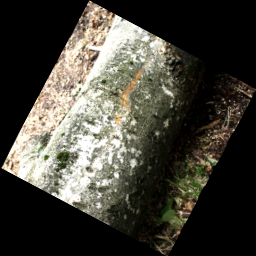

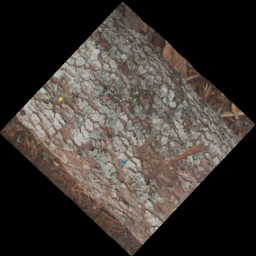

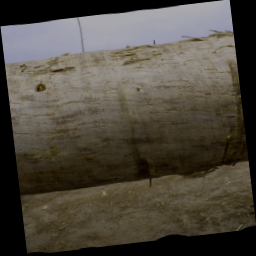

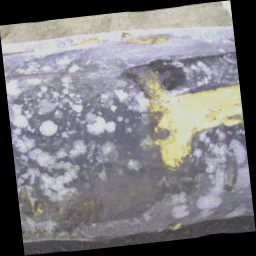

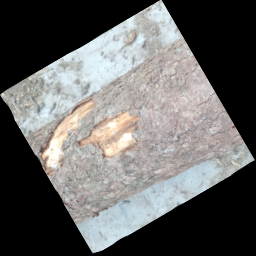

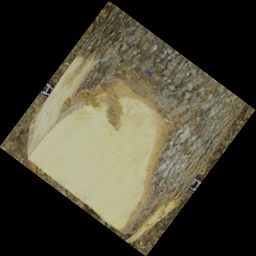

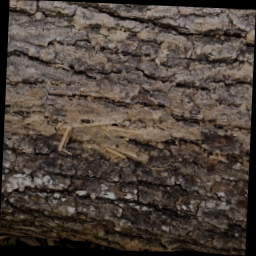

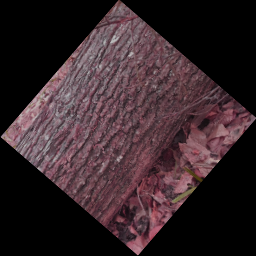

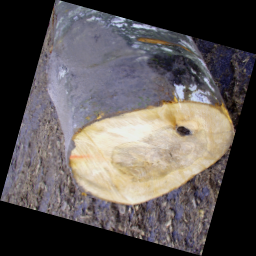

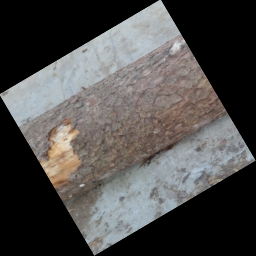

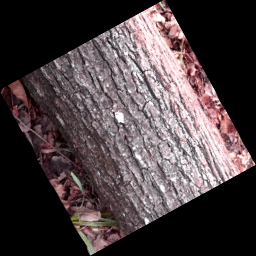

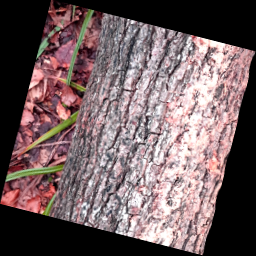

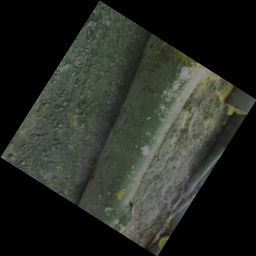

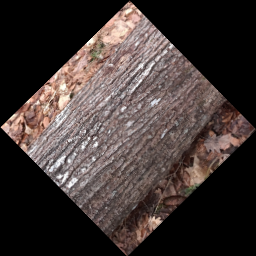

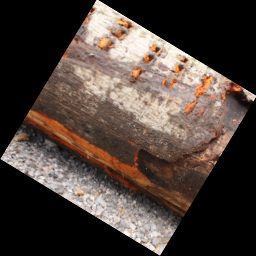

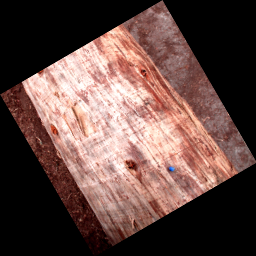

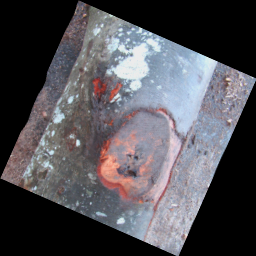

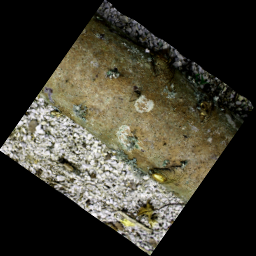

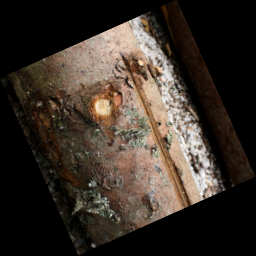

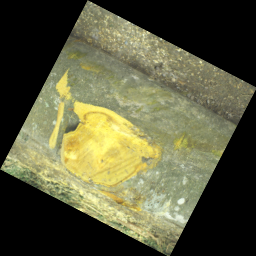

In [7]:
# preview a batch
images, masks = next(itr)
# unnormalize images for visualization
images = images * torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1) + torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)
print(f"Batch of images shape: {images.shape, images.dtype, images.device}")

from PIL import Image
import numpy as np

for image in images:
    Image.fromarray((image.permute(1, 2, 0).numpy() * 255).astype(np.uint8)).show()

In [5]:
for batch in train_dataloader:
    images, masks = batch
    print(f"Images shape: {images.shape, images.dtype, images.device}")
    print(f"Masks shape: {masks.shape, masks.dtype, masks.device}")
    break

for batch in val_dataloader:
    images, masks = batch
    print(f"Images shape: {images.shape, images.dtype, images.device}")
    print(f"Masks shape: {masks.shape, masks.dtype, masks.device}")
    break

Images shape: (torch.Size([20, 3, 256, 256]), torch.float32, device(type='cpu'))
Masks shape: (torch.Size([20, 1, 256, 256]), torch.float32, device(type='cpu'))
Images shape: (torch.Size([1, 3, 256, 455]), torch.float32, device(type='cpu'))
Masks shape: (torch.Size([1, 1, 256, 455]), torch.float32, device(type='cpu'))


In [6]:
module = SegModule(cfg.module)

logger = TensorBoardLogger(
    save_dir=".",
    name="",
    version="",
    default_hp_metric=False,
)

checkpoint_callback = L.pytorch.callbacks.ModelCheckpoint(
    monitor="val_dice",  # Name of the metric you logged in validation_step
    mode="max",  # We want the highest (maximum) value
    save_top_k=1,  # Only keep the single best model
    filename="best-model-{epoch:02d}-{val_dice:.4f}",
    save_last=True,  # Also keep a 'last.ckpt' for resuming
)

trainer = L.Trainer(
    max_epochs=cfg.total_epochs,
    accelerator="cuda",
    devices=[1],
    log_every_n_steps=10,
    callbacks=[checkpoint_callback],
    check_val_every_n_epoch=5,
    logger=logger,
)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [ ]:
try:
    trainer.fit(module, train_dataloader, val_dataloader)
except KeyboardInterrupt:
    print("Training interrupted. Saving current model state...")
except Exception as e:
    print(f"An error occurred during training: {e}")